In [1]:
import os
import sys

module_path = os.path.join(os.getcwd(), '..', 'module')
sys.path.append(module_path)

from Data_preparation import data_for_clust
from Data_preparation import quantity_executors
from Data_preparation import quantity_all
from sklearn.cluster import KMeans
from sklearn.preprocessing import MinMaxScaler
from sklearn.cluster import DBSCAN

import pandas as pd
# pd.set_option('display.float_format', '{:,.2f}'.format)
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.cluster.hierarchy import dendrogram, linkage, fcluster
from scipy.spatial.distance import pdist

from sklearn.cluster import KMeans, MeanShift, AgglomerativeClustering

from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import MinMaxScaler

In [2]:
#Загружаем исходные данные 
not_changed_df = pd.read_excel('../../data/Здания_Финальная_версия_ред.xlsx', 'Финальная ред')

not_changed_df['ИНН исполнителя'] = not_changed_df['ИНН исполнителя'].apply(
        lambda x: f"{int(x):.0f}" if pd.notna(x) else ''
    )

not_changed_df.head()

,Реестровый номер контракта,ИНН исполнителя,Наименование исполнителя,Статус контракта,Номер извещения,Дата заключения контракта,Дата окончания исполнения контракта,Цена контракта,Фактически оплачено,Основание расторжения контракта,Причина расторжения контракта,Неустойки (штрафы и пени),Включение в реестр недобросовестных поставщиков,Доходы,Расходы,Прибыль(убыток),ОКВЭД
0,2780515018525000010,7839128195,"ОБЩЕСТВО С ОГРАНИЧЕННОЙ ОТВЕТСТВЕННОСТЬЮ ""АЭФТ...",Исполнение завершено,3.722002e+17,2025-06-09,2025-12-31,78118.22,78118.22,NaN,NaN,Нет,нет,30983000.0,30753000.0,230000.0,Обеспечение работоспособности тепловых сетей
1,2780514542825000014,7839128195,"ОБЩЕСТВО С ОГРАНИЧЕННОЙ ОТВЕТСТВЕННОСТЬЮ ""АЭФТ...",Исполнение завершено,3.722001e+17,2025-06-02,2025-12-31,88272.19,88272.19,NaN,NaN,Нет,нет,30983000.0,30753000.0,230000.0,Обеспечение работоспособности тепловых сетей
2,2780514943025000017,7839128195,"ОБЩЕСТВО С ОГРАНИЧЕННОЙ ОТВЕТСТВЕННОСТЬЮ ""АЭФТ...",Исполнение завершено,3.722001e+17,2025-06-02,2025-12-31,329751.93,329751.93,NaN,NaN,Нет,нет,30983000.0,30753000.0,230000.0,Обеспечение работоспособности тепловых сетей
3,2780514920725000015,7839128195,"ОБЩЕСТВО С ОГРАНИЧЕННОЙ ОТВЕТСТВЕННОСТЬЮ ""АЭФТ...",Исполнение завершено,3.722001e+17,2025-06-02,2025-12-31,119338.94,119338.94,NaN,NaN,Нет,нет,30983000.0,30753000.0,230000.0,Обеспечение работоспособности тепловых сетей
4,2780514540325000007,7839128195,"ОБЩЕСТВО С ОГРАНИЧЕННОЙ ОТВЕТСТВЕННОСТЬЮ ""АЭФТ...",Исполнение завершено,3.722001e+17,2025-05-31,2025-12-31,155338.94,155338.94,NaN,NaN,Нет,нет,30983000.0,30753000.0,230000.0,Обеспечение работоспособности тепловых сетей


In [3]:
not_changed_df["Успешный контракт"] = np.where((not_changed_df["Статус контракта"] == "Исполнение завершено") 
                                     | (not_changed_df["Фактически оплачено"]/not_changed_df["Цена контракта"] > 0.85) 
                                     & (not_changed_df["Основание расторжения контракта"]
                                        .str
                                        .contains('соглашение', case = False))
                                     & not_changed_df["Причина расторжения контракта"]
                                        .str
                                        .contains(
                                         "соглашение|соглашению|в соответствии с фактическим объемом|уменьшение объема указываемых услуг|окончание срока оказания услуг",
                                         case=False), 1, 0)

In [4]:
not_changed_df.head(50)

,Реестровый номер контракта,ИНН исполнителя,Наименование исполнителя,Статус контракта,Номер извещения,Дата заключения контракта,Дата окончания исполнения контракта,Цена контракта,Фактически оплачено,Основание расторжения контракта,Причина расторжения контракта,Неустойки (штрафы и пени),Включение в реестр недобросовестных поставщиков,Доходы,Расходы,Прибыль(убыток),ОКВЭД,Успешный контракт
0,2780515018525000010,7839128195,"ОБЩЕСТВО С ОГРАНИЧЕННОЙ ОТВЕТСТВЕННОСТЬЮ ""АЭФТ...",Исполнение завершено,3.722002e+17,2025-06-09,2025-12-31,78118.22,78118.22,NaN,NaN,Нет,нет,30983000.0,30753000.0,230000.0,Обеспечение работоспособности тепловых сетей,1
1,2780514542825000014,7839128195,"ОБЩЕСТВО С ОГРАНИЧЕННОЙ ОТВЕТСТВЕННОСТЬЮ ""АЭФТ...",Исполнение завершено,3.722001e+17,2025-06-02,2025-12-31,88272.19,88272.19,NaN,NaN,Нет,нет,30983000.0,30753000.0,230000.0,Обеспечение работоспособности тепловых сетей,1
2,2780514943025000017,7839128195,"ОБЩЕСТВО С ОГРАНИЧЕННОЙ ОТВЕТСТВЕННОСТЬЮ ""АЭФТ...",Исполнение завершено,3.722001e+17,2025-06-02,2025-12-31,329751.93,329751.93,NaN,NaN,Нет,нет,30983000.0,30753000.0,230000.0,Обеспечение работоспособности тепловых сетей,1
3,2780514920725000015,7839128195,"ОБЩЕСТВО С ОГРАНИЧЕННОЙ ОТВЕТСТВЕННОСТЬЮ ""АЭФТ...",Исполнение завершено,3.722001e+17,2025-06-02,2025-12-31,119338.94,119338.94,NaN,NaN,Нет,нет,30983000.0,30753000.0,230000.0,Обеспечение работоспособности тепловых сетей,1
4,2780514540325000007,7839128195,"ОБЩЕСТВО С ОГРАНИЧЕННОЙ ОТВЕТСТВЕННОСТЬЮ ""АЭФТ...",Исполнение завершено,3.722001e+17,2025-05-31,2025-12-31,155338.94,155338.94,NaN,NaN,Нет,нет,30983000.0,30753000.0,230000.0,Обеспечение работоспособности тепловых сетей,1
5,2780514545025000007,7839128195,"ОБЩЕСТВО С ОГРАНИЧЕННОЙ ОТВЕТСТВЕННОСТЬЮ ""АЭФТ...",Исполнение завершено,3.722001e+17,2025-06-02,2025-12-31,78118.22,78118.22,NaN,NaN,Нет,нет,30983000.0,30753000.0,230000.0,Обеспечение работоспособности тепловых сетей,1
6,2780516644225000010,7839128195,"ОБЩЕСТВО С ОГРАНИЧЕННОЙ ОТВЕТСТВЕННОСТЬЮ ""АЭФТ...",Исполнение завершено,3.722001e+17,2025-06-02,2025-12-31,119338.94,119338.94,NaN,NaN,Да,нет,30983000.0,30753000.0,230000.0,Обеспечение работоспособности тепловых сетей,1
7,2780514935925000013,7839128195,"ОБЩЕСТВО С ОГРАНИЧЕННОЙ ОТВЕТСТВЕННОСТЬЮ ""АЭФТ...",Исполнение завершено,3.722001e+17,2025-06-02,2025-12-31,108528.16,108528.16,NaN,NaN,Нет,нет,30983000.0,30753000.0,230000.0,Обеспечение работоспособности тепловых сетей,1
8,2780514490725000020,7839128195,"ОБЩЕСТВО С ОГРАНИЧЕННОЙ ОТВЕТСТВЕННОСТЬЮ ""АЭФТ...",Исполнение завершено,3.722002e+17,2025-06-10,2025-12-31,88272.19,88272.19,NaN,NaN,Нет,нет,30983000.0,30753000.0,230000.0,Обеспечение работоспособности тепловых сетей,1
9,2780514541025000019,7839128195,"ОБЩЕСТВО С ОГРАНИЧЕННОЙ ОТВЕТСТВЕННОСТЬЮ ""АЭФТ...",Исполнение завершено,3.722001e+17,2025-06-02,2025-12-31,176544.38,176544.38,NaN,NaN,Нет,нет,30983000.0,30753000.0,230000.0,Обеспечение работоспособности тепловых сетей,1


In [5]:
not_changed_df["Основание расторжения контракта"].unique()

array([nan, 'Соглашение сторон',
       'Односторонний отказ заказчика от исполнения контракта в соответствии с гражданским законодательством',
       'Односторонний отказ поставщика (подрядчика, исполнителя) от исполнения контракта в соответствии с гражданским законодательством'],
      dtype=object)

In [6]:
pd.set_option('display.max_rows', None)
pd.DataFrame(not_changed_df["Причина расторжения контракта"].unique())

,0
0,NaN
1,Соглашение сторон
2,На основании ч. 8 ст. 95 Федерального закона о...
3,в соответствии с фактическим объемом
4,в соответствии с фактическим объемом оказанных...
5,отсутствует потребность заказчика в дальнейшем...
6,Соглашение о расторжении Контракт № 0372200048...
7,В соответствии с Соглашением о расторжении
8,Соглашение о расторжении б/н от 18.08.2025\nСо...
9,На основании ч. 8 ст. 95 Федерального закона о...


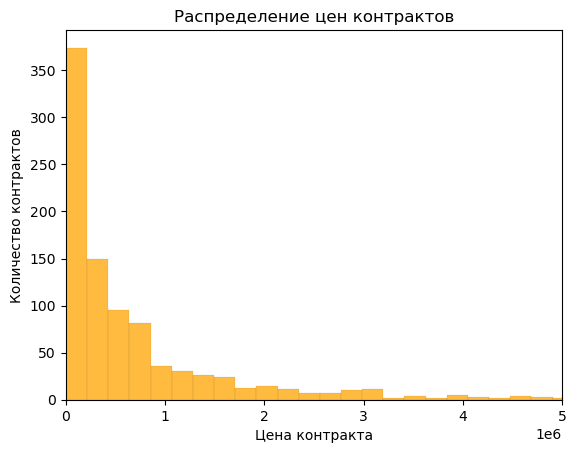

In [7]:
sns.histplot(not_changed_df["Цена контракта"], color = "orange")
plt.xlim(0, 5_000_000)
plt.title("Распределение цен контрактов")
plt.xlabel("Цена контракта")
plt.ylabel("Количество контрактов")
plt.show()

In [8]:
#Создаем данные для кластеризации в R
first_df = data_for_clust('../../data/Здания_Финальная_версия_ред.xlsx', 'Финальная ред')

first_df = first_df.drop(0).reset_index(drop=True)

clust_data = first_df[['ИНН исполнителя', 'Средняя цена контракта', 'Количество контрактов']]

clust_data = clust_data.copy()

clust_data['Средняя цена контракта log'] = np.log(clust_data['Средняя цена контракта'])
clust_data['Количество контрактов log'] = np.log(clust_data['Количество контрактов'])

clust_data_new = clust_data.drop(['Средняя цена контракта', 'ИНН исполнителя', 'Количество контрактов'], axis=1)

In [9]:
first_df.head(50)

,ИНН исполнителя,Сумма контрактов,Средняя цена контракта,Максимальная цена контракта,Сумма оплат,Средняя сумма оплат,Количество контрактов,Доходы,Расходы,Прибыль(убыток),Количество прекращенных контрактов,Неустойки (штрафы и пени),Включение в реестр недобросовестных поставщиков,Количество успешных контрактов
0,1001146420,200000.00,2.000000e+05,200000.00,199990.25,1.999902e+05,1,3.732000e+06,3.277000e+06,4.550000e+05,1,0,0,1
1,1001333318,280192.52,2.801925e+05,280192.52,246645.01,2.466450e+05,1,6.165900e+07,2.449100e+07,3.716800e+07,1,0,0,1
2,102002711630,786656.66,7.866567e+05,786656.66,786656.66,7.866567e+05,1,NaN,NaN,0.000000e+00,0,0,0,1
3,141701766795,204449.00,1.022245e+05,140000.00,74767.36,3.738368e+04,2,NaN,NaN,0.000000e+00,2,0,1,0
4,2100009963,554000.00,2.770000e+05,438000.00,554000.00,2.770000e+05,2,1.756000e+06,7.290000e+05,1.027000e+06,0,0,0,2
5,211301376106,968446.40,9.684464e+05,968446.40,968446.40,9.684464e+05,1,NaN,NaN,0.000000e+00,0,0,0,1
6,2312224779,60000.00,6.000000e+04,60000.00,60000.00,6.000000e+04,1,NaN,NaN,0.000000e+00,0,0,0,1
7,233012683520,108000.00,1.080000e+05,108000.00,108000.00,1.080000e+05,1,NaN,NaN,0.000000e+00,0,0,0,1
8,235200270142,4418752.83,2.209376e+06,2342721.45,4297923.68,2.148962e+06,2,NaN,NaN,0.000000e+00,2,0,0,0
9,2462211810,7427253.88,1.856813e+06,6750881.48,7347828.63,1.836957e+06,4,5.994030e+08,5.863600e+08,1.304300e+07,0,0,0,4


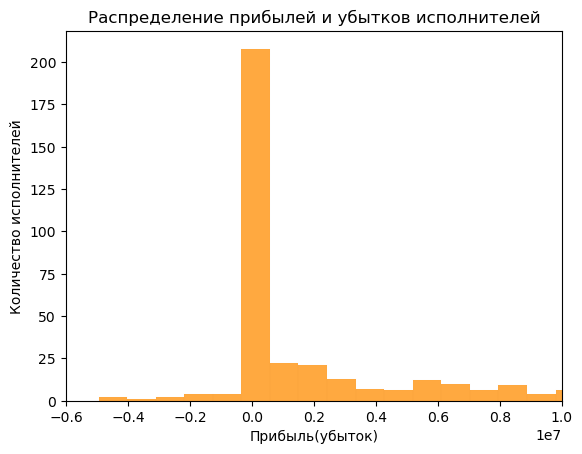

In [10]:
sns.histplot(first_df["Прибыль(убыток)"], bins = 5000, color = "#FF8C00")
plt.xlim(-6000000,10000000)
plt.title("Распределение прибылей и убытков исполнителей")
plt.xlabel("Прибыль(убыток)")
plt.ylabel("Количество исполнителей")
plt.show()

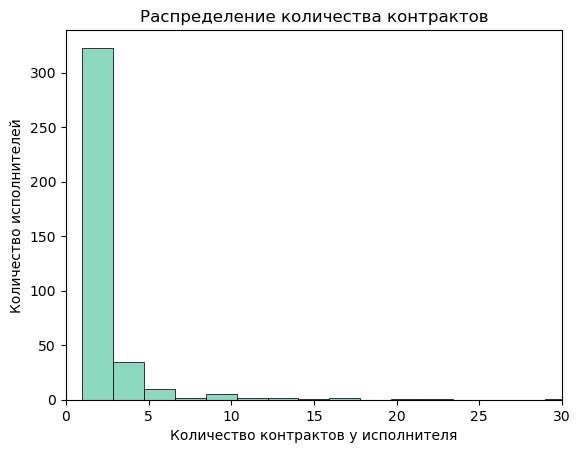

In [11]:
sns.histplot(first_df["Количество контрактов"], bins = 60, color = "#66CDAA")
plt.xlim(0, 30)
plt.title("Распределение количества контрактов")
plt.xlabel("Количество контрактов у исполнителя")
plt.ylabel("Количество исполнителей")
plt.show()

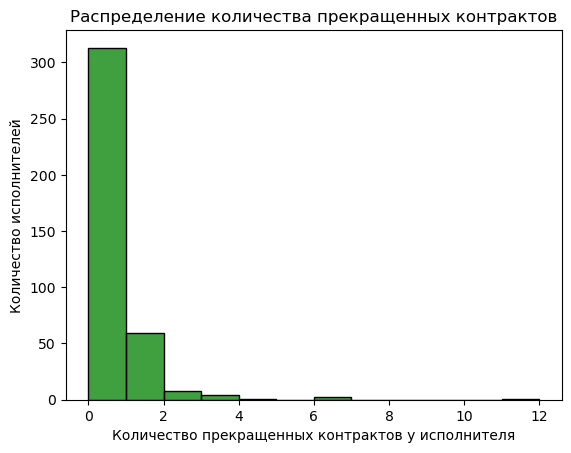

In [12]:
sns.histplot(first_df["Количество прекращенных контрактов"], bins = 12, color = "green")
plt.title("Распределение количества прекращенных контрактов")
plt.xlabel("Количество прекращенных контрактов у исполнителя")
plt.ylabel("Количество исполнителей")
plt.show()

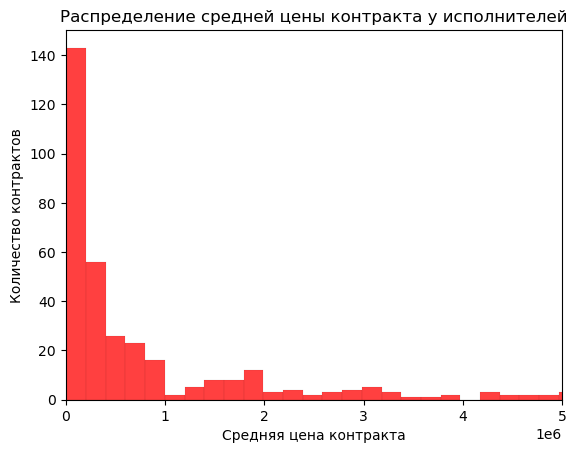

In [13]:
sns.histplot(first_df["Средняя цена контракта"], bins = 800, color = "red")
plt.xlim(0, 5_000_000)
plt.title("Распределение средней цены контракта у исполнителей")
plt.xlabel("Средняя цена контракта")
plt.ylabel("Количество контрактов")
plt.show()

In [14]:
clust_data.describe()

,Средняя цена контракта,Количество контрактов,Средняя цена контракта log,Количество контрактов log
count,3.880000e+02,388.000000,388.000000,388.000000
mean,4.348837e+06,2.574742,13.052647,0.412025
std,1.423191e+07,7.059151,2.089907,0.740977
min,4.611630e+03,1.000000,8.436337,0.000000
25%,1.128394e+05,1.000000,11.633714,0.000000
50%,3.599197e+05,1.000000,12.793635,0.000000
75%,1.862629e+06,2.000000,14.437485,0.693147
max,1.588530e+08,113.000000,18.883490,4.727388


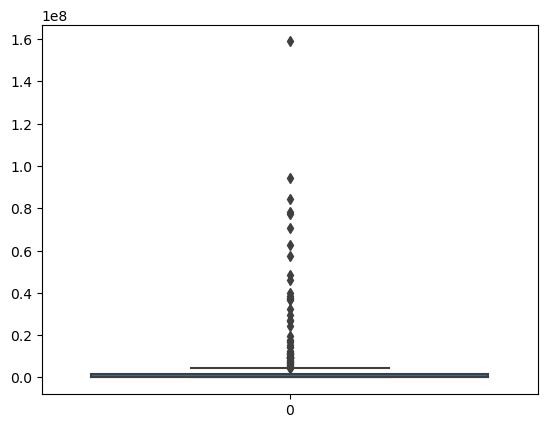

In [15]:
#Графики выбросов
sns.boxplot(clust_data["Средняя цена контракта"])
plt.show()


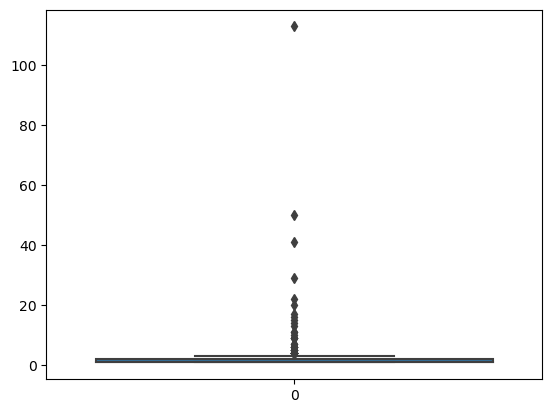

In [16]:
sns.boxplot(clust_data["Количество контрактов"])
plt.show()

In [17]:
# df_no_outliers = clust_data
# for i in range(7):
    
#     Q1 = df_no_outliers['Средняя цена контракта'].quantile(0.25)
#     Q3 = df_no_outliers['Средняя цена контракта'].quantile(0.75)
#     IQR = Q3 - Q1

#     low = Q1 - 1.5 * IQR
#     high = Q3 + 1.5 * IQR

#     df_no_outliers = clust_data[(clust_data['Средняя цена контракта'] >= low) & (clust_data['Средняя цена контракта'] <= high)]
    

In [18]:

# for j in range(3):
    
#     Q1_2 = df_no_outliers['Количество контрактов'].quantile(0.25)
#     Q3_2 = df_no_outliers['Количество контрактов'].quantile(0.75)
#     IQR_2 = Q3_2 - Q1_2

#     low_2 = Q1_2 - 1.5 * IQR_2
#     high_2 = Q3_2 + 1.5 * IQR_2

#     df_no_outliers = df_no_outliers[(df_no_outliers['Количество контрактов'] >= low_2) & (df_no_outliers['Количество контрактов'] <= high_2)]

In [19]:
def winsorize_df(df, cols, low=0.25, high=0.75):
    df_out = df.copy()
    for c in cols:
        ql, qh = df_out[c].quantile([low, high])
        df_out[c] = df_out[c].clip(ql, qh)
    return df_out

df_no_outliers = winsorize_df(clust_data, ['Средняя цена контракта'], 0.15, 0.85)
df_no_outliers = winsorize_df(df_no_outliers, ['Количество контрактов'], 0.05, 0.95)


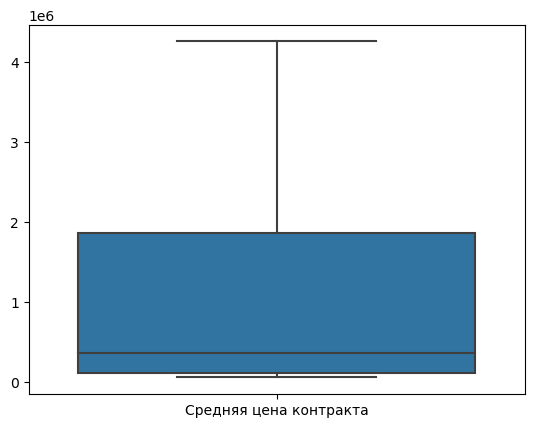

In [20]:
# df_no_outliers = clust_data
sns.boxplot(df_no_outliers[["Средняя цена контракта"]])
plt.show()

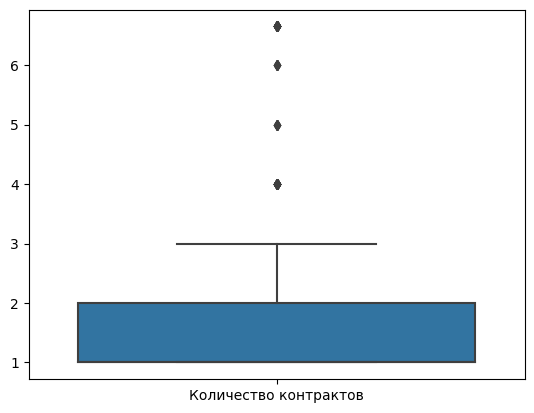

In [21]:
sns.boxplot(df_no_outliers[["Количество контрактов"]])
plt.show()

In [22]:
df_no_outliers.describe()

,Средняя цена контракта,Количество контрактов,Средняя цена контракта log,Количество контрактов log
count,3.880000e+02,388.000000,388.000000,388.000000
mean,1.210010e+06,1.804124,13.052647,0.412025
std,1.531330e+06,1.528847,2.089907,0.740977
min,5.503195e+04,1.000000,8.436337,0.000000
25%,1.128394e+05,1.000000,11.633714,0.000000
50%,3.599197e+05,1.000000,12.793635,0.000000
75%,1.862629e+06,2.000000,14.437485,0.693147
max,4.263139e+06,6.650000,18.883490,4.727388


In [23]:
#Стандартизация

In [24]:
df_no_outliers.iloc[ :,1:]

,Средняя цена контракта,Количество контрактов,Средняя цена контракта log,Количество контрактов log
0,2.000000e+05,1.00,12.206073,0.000000
1,2.801925e+05,1.00,12.543232,0.000000
2,7.866567e+05,1.00,13.575547,0.000000
3,1.022245e+05,2.00,11.534927,0.693147
4,2.770000e+05,2.00,12.531773,0.693147
5,9.684464e+05,1.00,13.783448,0.000000
6,6.000000e+04,1.00,11.002100,0.000000
7,1.080000e+05,1.00,11.589887,0.000000
8,2.209376e+06,2.00,14.608221,0.693147
9,1.856813e+06,4.00,14.434372,1.386294


In [25]:
scaler = MinMaxScaler()
scaled = df_no_outliers.copy()
scaled_2 = clust_data.copy()

scaled.iloc[:, 1:] = scaler.fit_transform(scaled.iloc[:, 1:])
scaled_2.iloc[:, 1:] = scaler.fit_transform(scaled_2.iloc[:, 1:])

df_scaled = pd.DataFrame(scaled, columns=df_no_outliers.columns)
df_scaled_2 = pd.DataFrame(scaled_2, columns=clust_data.columns)

In [26]:
#Иерархическая кластеризация
from scipy.cluster.hierarchy import dendrogram, linkage
from matplotlib import pyplot as plt

In [27]:
#Матрица слияний для необработанных занчений
# Z = linkage(df_scaled[["Средняя цена контракта", "Количество контрактов"]], method='ward', metric='euclidean', optimal_ordering=True)

Z = linkage(df_scaled_2[["Средняя цена контракта log", "Количество контрактов log"]], method='ward', metric='euclidean', optimal_ordering=True)

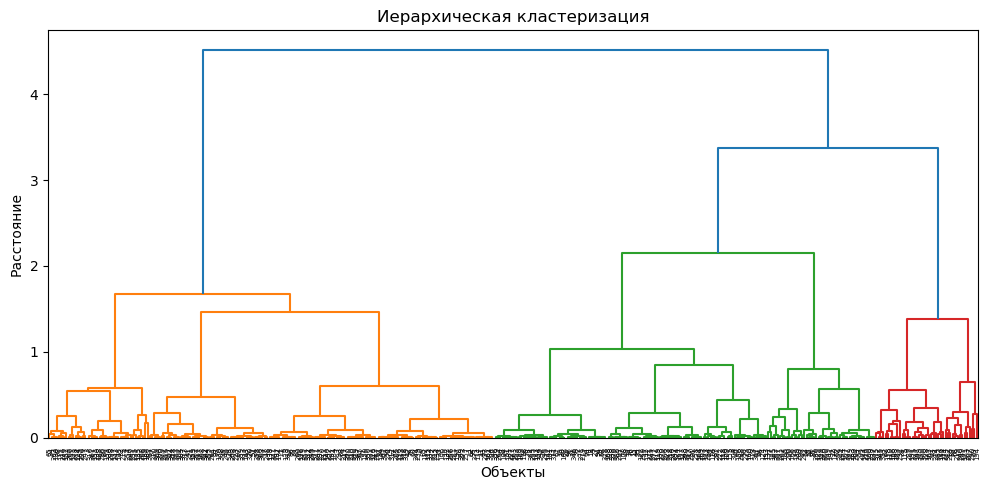

In [28]:
plt.figure(figsize=(10, 5))
dendrogram(Z, leaf_rotation=90)
plt.title("Иерархическая кластеризация")
plt.xlabel("Объекты")
plt.ylabel("Расстояние")
plt.tight_layout()
plt.show()

In [29]:
k = 3
labels_k = fcluster(Z, t=k, criterion='maxclust')

In [30]:
df_hc = clust_data.copy()
df_hc['Cluster'] = labels_k

summary = df_hc.groupby('Cluster')[["Средняя цена контракта", "Количество контрактов"]].agg(['mean','count'])
print(summary)

        Средняя цена контракта       Количество контрактов      
                          mean count                  mean count
Cluster                                                         
1                 1.268921e+05   186              1.387097   186
2                 1.006583e+07   159              1.301887   159
3                 1.471609e+06    43             12.418605    43


In [31]:
df_hc.describe()

,Средняя цена контракта,Количество контрактов,Средняя цена контракта log,Количество контрактов log,Cluster
count,3.880000e+02,388.000000,388.000000,388.000000,388.000000
mean,4.348837e+06,2.574742,13.052647,0.412025,1.631443
std,1.423191e+07,7.059151,2.089907,0.740977,0.674942
min,4.611630e+03,1.000000,8.436337,0.000000,1.000000
25%,1.128394e+05,1.000000,11.633714,0.000000,1.000000
50%,3.599197e+05,1.000000,12.793635,0.000000,2.000000
75%,1.862629e+06,2.000000,14.437485,0.693147,2.000000
max,1.588530e+08,113.000000,18.883490,4.727388,3.000000


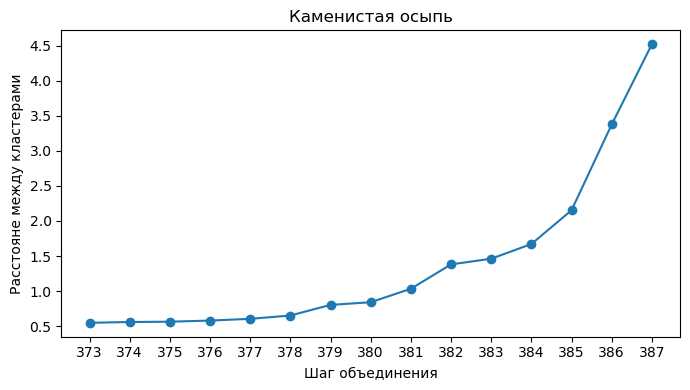

In [32]:
heights = Z[:, 2]
steps = np.arange(1, len(heights)+1)

last = 15
sel = np.arange(len(heights)-last, len(heights))
plt.figure(figsize=(7,4))
plt.plot(sel+1, heights[sel], marker='o')
plt.title("Каменистая осыпь")
plt.xlabel("Шаг объединения")
plt.ylabel("Расстояне между кластерами")
plt.xticks(sel + 1)
plt.tight_layout()
plt.show()

In [33]:
clust_data_with_labels = pd.concat(
    [clust_data[["ИНН исполнителя", "Средняя цена контракта", "Количество контрактов"]]
    .reset_index(drop=True), 
    pd.DataFrame(labels_k, columns=["Cluster"])
    .reset_index(drop=True)], 
    axis = 1)

In [34]:
clust_data_with_labels.describe()

,Средняя цена контракта,Количество контрактов,Cluster
count,3.880000e+02,388.000000,388.000000
mean,4.348837e+06,2.574742,1.631443
std,1.423191e+07,7.059151,0.674942
min,4.611630e+03,1.000000,1.000000
25%,1.128394e+05,1.000000,1.000000
50%,3.599197e+05,1.000000,2.000000
75%,1.862629e+06,2.000000,2.000000
max,1.588530e+08,113.000000,3.000000


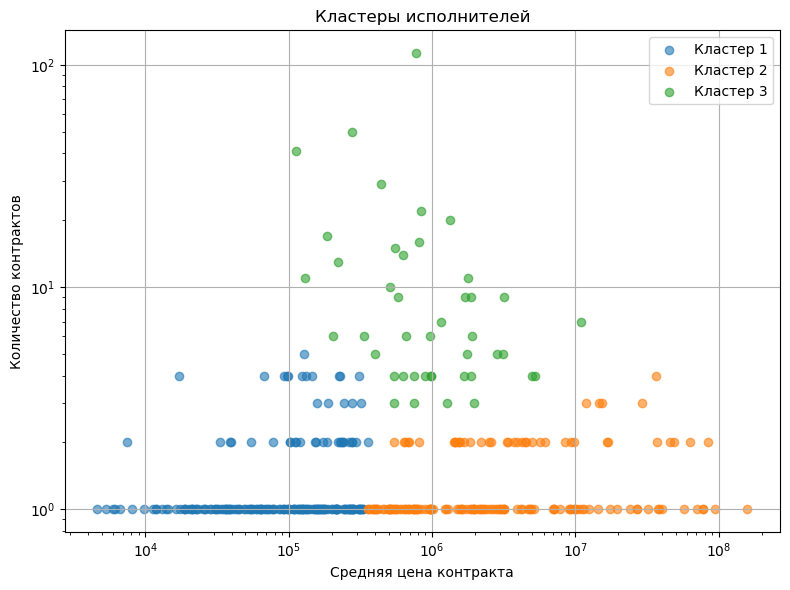

In [35]:

plt.figure(figsize=(8, 6))

for cl in sorted(clust_data_with_labels["Cluster"].unique()):
    subset = clust_data_with_labels[clust_data_with_labels["Cluster"] == cl]
    plt.scatter(subset["Средняя цена контракта"],
                subset["Количество контрактов"],
                alpha=0.6,
                label=f"Кластер {cl}")

plt.xscale("log")  
plt.yscale("log")    
    
plt.xlabel("Средняя цена контракта")
plt.ylabel("Количество контрактов")
plt.title("Кластеры исполнителей")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


In [36]:
#Для обработанных данных
Z_no_outliers = linkage(df_scaled[["Средняя цена контракта", "Количество контрактов"]], method='ward', metric='euclidean', optimal_ordering=True)

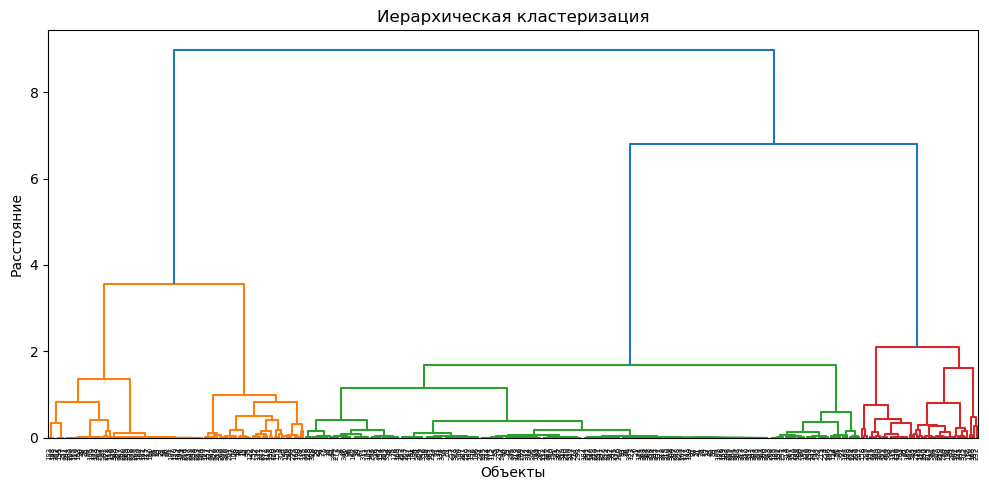

In [37]:
plt.figure(figsize=(10, 5))
dendrogram(Z_no_outliers, leaf_rotation=90)
plt.title("Иерархическая кластеризация")
plt.xlabel("Объекты")
plt.ylabel("Расстояние")
plt.tight_layout()
plt.show()

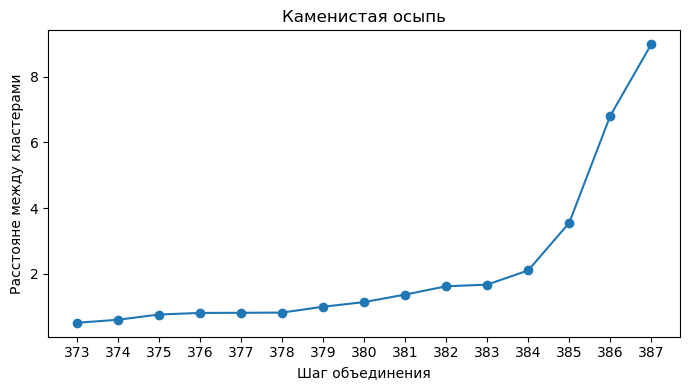

In [38]:
heights = Z_no_outliers[:, 2]
steps = np.arange(1, len(heights)+1)

last = 15
sel = np.arange(len(heights)-last, len(heights))
plt.figure(figsize=(7,4))
plt.plot(sel+1, heights[sel], marker='o')
plt.title("Каменистая осыпь")
plt.xlabel("Шаг объединения")
plt.ylabel("Расстояне между кластерами")
plt.xticks(sel + 1)
plt.tight_layout()
plt.show()

In [39]:
k_2 = 4
labels_k_2 = fcluster(Z_no_outliers, t=k_2, criterion='maxclust')

In [40]:
df_hc_2 = df_no_outliers.copy()
df_hc_2['Cluster'] = labels_k_2

summary = df_hc_2.groupby('Cluster')[["Средняя цена контракта", "Количество контрактов"]].agg(['mean','count'])
print(summary)

        Средняя цена контракта       Количество контрактов      
                          mean count                  mean count
Cluster                                                         
1                 4.215098e+06    65              1.569231    65
2                 2.129267e+06    42              1.357143    42
3                 2.696249e+05   232              1.193966   232
4                 8.881697e+05    49              5.387755    49


In [41]:
no_outliers_data_with_labels = pd.concat(
    [df_no_outliers[["ИНН исполнителя", "Средняя цена контракта", "Количество контрактов"]]
    .reset_index(drop=True), 
    pd.DataFrame(labels_k_2, columns=["Cluster"])
    .reset_index(drop=True)], 
    axis = 1)


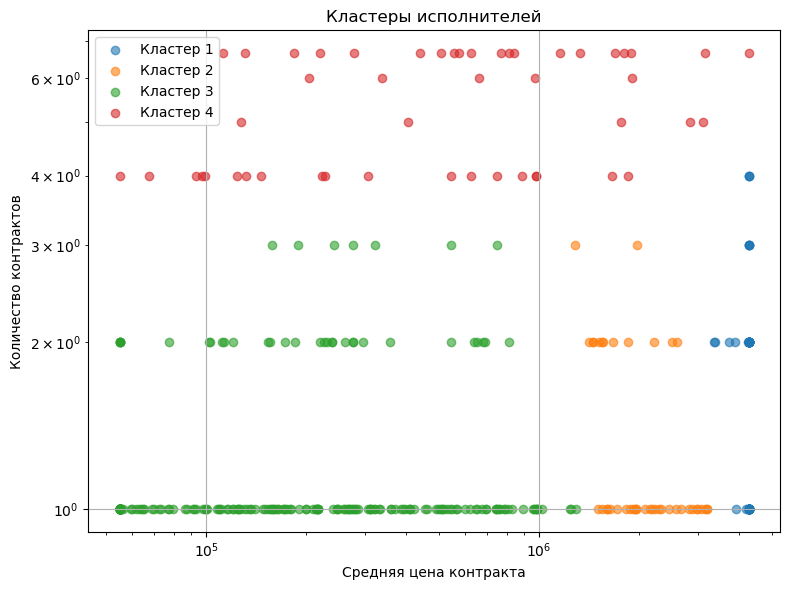

In [42]:

plt.figure(figsize=(8, 6))

for cl in sorted(no_outliers_data_with_labels["Cluster"].unique()):
    subset = no_outliers_data_with_labels[no_outliers_data_with_labels["Cluster"] == cl]
    plt.scatter(subset["Средняя цена контракта"],
                subset["Количество контрактов"],
                alpha=0.6,
                label=f"Кластер {cl}")

plt.xscale("log")  
plt.yscale("log")    
    
plt.xlabel("Средняя цена контракта")
plt.ylabel("Количество контрактов")
plt.title("Кластеры исполнителей")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


In [43]:
clust_data_ex = clust_data.copy()
clust_data_ex = clust_data_ex.drop(['Средняя цена контракта log', 'Количество контрактов log'], axis = 1)
clust_data_ex.head()

clust_data_ex.to_excel('Здания для кластеризации 2.xlsx', index=False)

In [44]:
#Загружаем результаты кластеризации 
clusters_df = pd.read_excel('../R/результаты_кластеризации.xlsx')

clusters_df.columns = [c.replace(".", " ") for c in clusters_df.columns]

clusters_df = clusters_df[["ИНН исполнителя", "Cluster"]]

In [45]:
#Выводим общие данные 
print(quantity_all(not_changed_df))

Общее количество контрактов: 1000
Общая сумма контрактов: 2838964547.38
Общее количество исполнителей: 389
None


In [46]:
#Подготовка сборного датасета

similarity_df = first_df.drop(["Сумма контрактов", "Сумма оплат"], axis = 1)

similarity = similarity_df.copy()

similarity['Рентабельность продаж'] = (( \
    similarity['Прибыль(убыток)'] / similarity['Доходы']) \
    .where(similarity['ИНН исполнителя'].astype(str).str.len() == 10)) \
    .replace([np.inf, -np.inf, np.nan], 0)

similarity['Доля прекращенных контрактов'] = (similarity['Количество прекращенных контрактов'] / similarity['Количество контрактов']) \
    .replace([np.inf, -np.inf, np.nan], 0)
    
similarity['Доля штрафных контрактов'] = (similarity['Неустойки (штрафы и пени)'] / similarity['Количество контрактов']) \
    .replace([np.inf, -np.inf, np.nan], 0)
    
similarity['Доля контракта от доходов'] = (( \
    similarity['Средняя цена контракта'] / similarity['Доходы']) \
    .where(similarity['ИНН исполнителя'].astype(str).str.len() == 10)) \
    .replace([np.inf, -np.inf, np.nan], 0)

similarity['Доля оплаты от цены контракта'] = (
    similarity['Средняя сумма оплат'] / similarity['Средняя цена контракта']
    )

similarity['Доля успешных контрактов'] = (
    similarity['Количество успешных контрактов'] / similarity['Количество контрактов']
    )

fin_cols = ["Прибыль(убыток)", "Доля контракта от доходов", "Рентабельность продаж"]
similarity["Прибыль(убыток)"] = np.log1p(similarity["Прибыль(убыток)"])

scaler = MinMaxScaler()
df_fin_scaled = pd.DataFrame(scaler.fit_transform(similarity[fin_cols]), columns = fin_cols)

# similarity["Финансовая устойчивость"] = df_fin_scaled.mean(axis = 1)


#Удаление столбцов чтобы избежать дублирования при join-е
similarity = similarity.drop([
                             "Доходы", "Расходы", "Прибыль(убыток)",
                             "Включение в реестр недобросовестных поставщиков"], axis = 1)

C:\Users\Alexander\anaconda3\Lib\site-packages\pandas\core\arraylike.py:402: RuntimeWarning: invalid value encountered in log1p
  result = getattr(ufunc, method)(*inputs, **kwargs)


In [47]:
#Подготовка данных 
clusters_df["ИНН исполнителя"] = clusters_df["ИНН исполнителя"].astype("object")

clusters_df['ИНН исполнителя'] = (
    clusters_df['ИНН исполнителя']
    .astype(str)                           
    .str.strip()                            
    .str.replace(r'\.0$', '', regex=True)   
    .str.replace(r'\D', '', regex=True)    
)

In [48]:
df_hc = df_hc[["ИНН исполнителя","Cluster"]]
df_hc_2 = df_hc_2[["ИНН исполнителя","Cluster"]]

In [49]:
full_df = pd.merge(not_changed_df, similarity, on="ИНН исполнителя", how="left")
full_df = pd.merge(full_df, df_hc, on="ИНН исполнителя", how="left")



In [50]:
full_df.describe()

,Реестровый номер контракта,Номер извещения,Цена контракта,Фактически оплачено,Доходы,Расходы,Прибыль(убыток),Успешный контракт,Средняя цена контракта,Максимальная цена контракта,Средняя сумма оплат,Количество контрактов,Количество прекращенных контрактов,Неустойки (штрафы и пени)_y,Количество успешных контрактов,Рентабельность продаж,Доля прекращенных контрактов,Доля штрафных контрактов,Доля контракта от доходов,Доля оплаты от цены контракта,Доля успешных контрактов,Cluster
count,1.000000e+03,7.420000e+02,1.000000e+03,9.840000e+02,7.250000e+02,7.250000e+02,9.990000e+02,1000.000000,9.990000e+02,9.990000e+02,9.990000e+02,999.000000,999.000000,999.000000,999.000000,999.000000,999.000000,999.000000,999.000000,999.000000,999.000000,999.000000
mean,2.658653e+18,3.493351e+17,2.838965e+06,2.794094e+06,3.106474e+08,2.699410e+08,2.954165e+07,0.932000,2.828724e+06,4.718918e+06,2.775953e+06,21.878879,1.386386,0.801802,21.313313,0.081016,0.115115,0.045045,0.109769,0.986543,0.931932,2.276276
std,3.381601e+17,1.522037e+17,1.084585e+07,1.082103e+07,1.536942e+09,1.198246e+09,3.123342e+08,0.251872,1.021052e+07,1.289413e+07,1.013732e+07,35.113020,2.313343,1.589910,34.982717,0.157645,0.245691,0.145491,1.601595,0.104763,0.192246,0.846866
min,1.502705e+18,1.451000e+17,1.207380e+03,1.207380e+03,0.000000e+00,2.680000e+05,-2.982300e+07,0.000000,4.611630e+03,4.611630e+03,4.611630e+03,1.000000,0.000000,0.000000,0.000000,-1.282481,0.000000,0.000000,0.000000,0.040000,0.000000,1.000000
25%,2.780212e+18,2.155750e+17,1.193389e+05,1.144001e+05,2.900300e+07,2.668500e+07,0.000000e+00,1.000000,1.867897e+05,3.297519e+05,1.844714e+05,1.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.990767,0.991150,1.000000
50%,2.780644e+18,3.722001e+17,3.901606e+05,3.744500e+05,5.138800e+07,4.841100e+07,2.318000e+06,1.000000,5.751067e+05,1.856058e+06,5.554017e+05,4.000000,0.000000,0.000000,4.000000,0.022269,0.000000,0.000000,0.004768,1.000000,1.000000,3.000000
75%,2.781703e+18,3.722002e+17,1.186850e+06,1.084434e+06,1.259190e+08,1.142080e+08,6.627000e+06,1.000000,1.311432e+06,3.501801e+06,1.201223e+06,22.000000,1.000000,1.000000,21.000000,0.080057,0.076923,0.034483,0.014983,1.000000,1.000000,3.000000
max,3.781703e+18,8.725000e+17,1.588530e+08,1.588530e+08,1.965510e+10,1.507835e+10,4.576749e+09,1.000000,1.588530e+08,1.588530e+08,1.588530e+08,113.000000,12.000000,5.000000,112.000000,0.917967,1.000000,1.000000,35.733845,1.587558,1.000000,3.000000


In [51]:
# full_df = full_df.dropna(subset=["ИНН исполнителя"])
# full_df = full_df[full_df["ИНН исполнителя"].str.strip() != ""]
# full_df = full_df.reset_index(drop=True)

full_df = full_df.dropna(subset=["ИНН исполнителя"])
full_df = full_df.dropna(subset=["Cluster"])
full_df = full_df[full_df["ИНН исполнителя"].str.strip() != ""]
full_df = full_df.reset_index(drop=True)

In [52]:
full_df["Статус контракта"] = (full_df["Статус контракта"] == "Исполнение завершено").astype(int)

full_df["Включение в реестр недобросовестных поставщиков"] = (full_df["Включение в реестр недобросовестных поставщиков"] == "да").astype(int)

In [53]:
full_df["ЛогЦена"] = np.log1p(full_df["Цена контракта"].clip(lower=0))
full_df["ЛогПрибыль"] = np.log1p(full_df["Прибыль(убыток)"].clip(lower=0))
# full_df["Доля оплаты"] = full_df["Фактически оплачено"]/full_df["Цена контракта"]

scaler = MinMaxScaler()

cols_to_scale = ["ЛогЦена", "ЛогПрибыль"]

full_df[cols_to_scale] = scaler.fit_transform(full_df[cols_to_scale])


In [54]:
full_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 999 entries, 0 to 998
Data columns (total 34 columns):
 #   Column                                           Non-Null Count  Dtype         
---  ------                                           --------------  -----         
 0   Реестровый номер контракта                       999 non-null    int64         
 1   ИНН исполнителя                                  999 non-null    object        
 2   Наименование исполнителя                         999 non-null    object        
 3   Статус контракта                                 999 non-null    int32         
 4   Номер извещения                                  742 non-null    float64       
 5   Дата заключения контракта                        982 non-null    datetime64[ns]
 6   Дата окончания исполнения контракта              999 non-null    datetime64[ns]
 7   Цена контракта                                   999 non-null    float64       
 8   Фактически оплачено                     

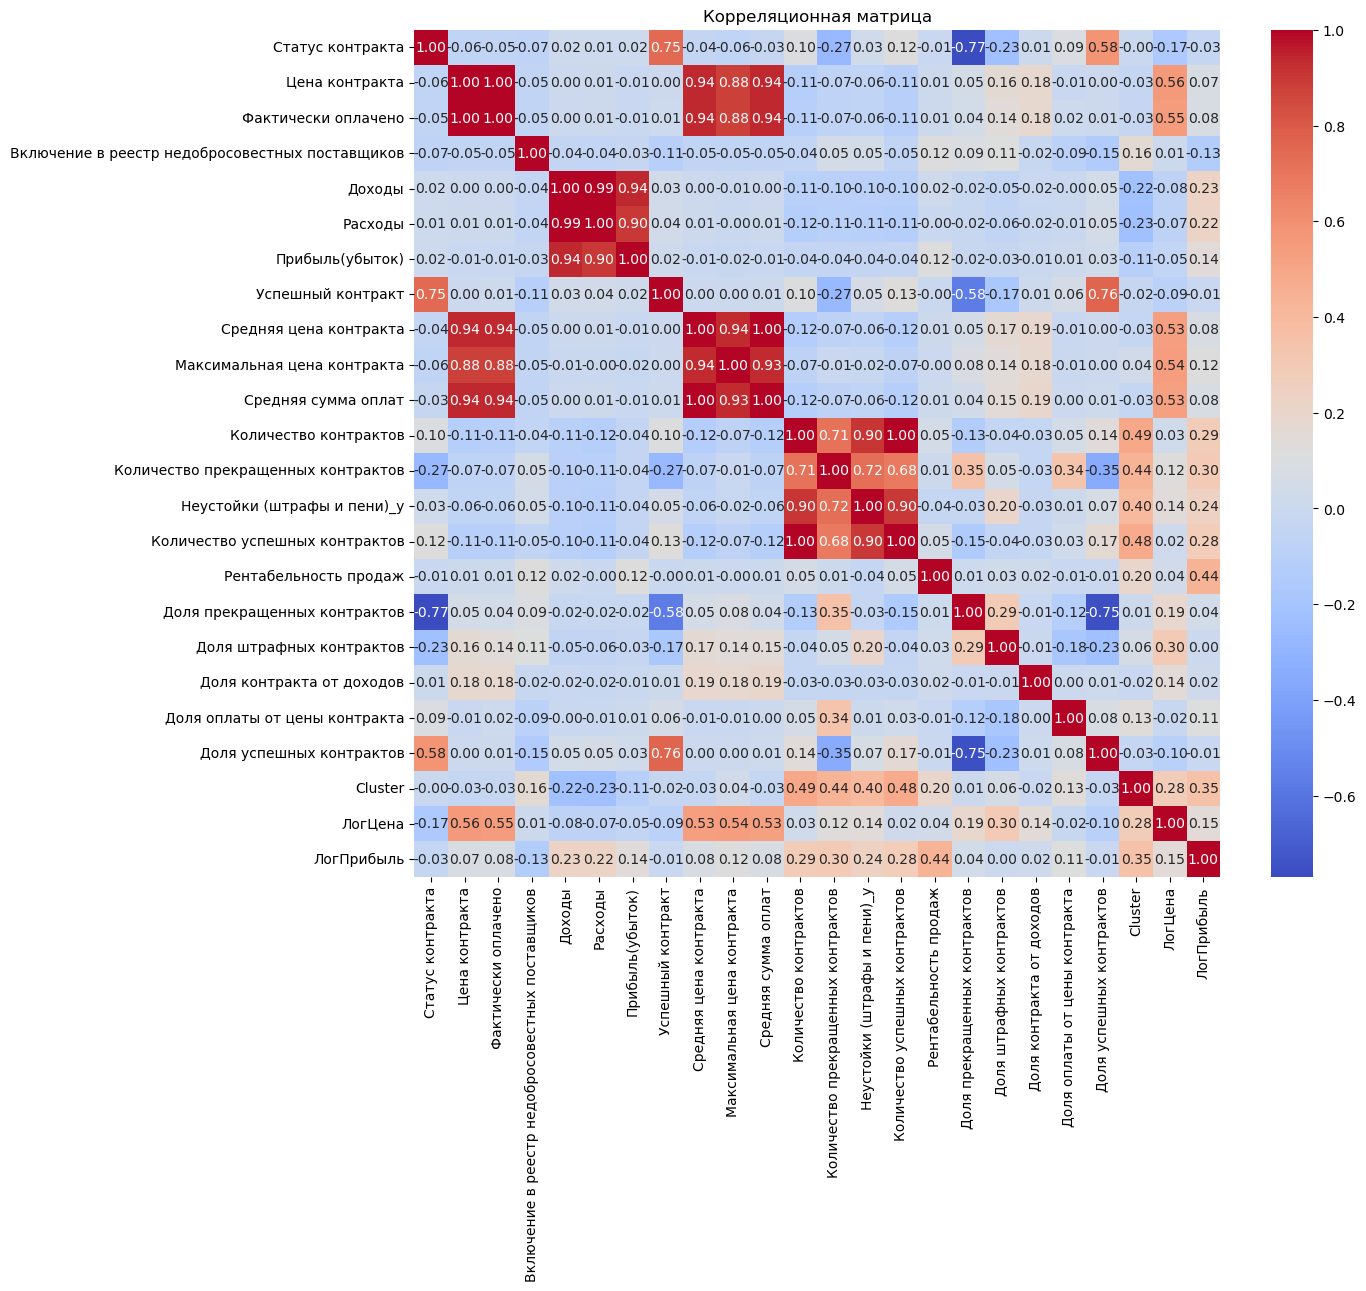

In [55]:
numeric_df = full_df.select_dtypes(include=["number"])
numeric_df = numeric_df.drop(["Реестровый номер контракта", "Номер извещения"], axis = 1)

corr_matrix = numeric_df.corr()

plt.figure(figsize=(13,11))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", cbar=True)
plt.title("Корреляционная матрица")
plt.show()

In [56]:
full_df = pd.get_dummies(full_df, columns = ["Cluster"], drop_first = True)

In [57]:
#Модели

In [94]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix

In [133]:
#Переменные 

features = [
        'Фактически оплачено',
        'Доля успешных контрактов',
#         'Включение в реестр недобросовестных поставщиков',
#         'Доля оплаты от цены контракта',
#         'Доля штрафных контрактов',
#         'Количество контрактов',
#         'Количество прекращенных контрактов',
#         'Количество успешных контрактов',
        'ЛогЦена',
        'Cluster_2.0',
         'Cluster_3.0'
#           'Cluster_4.0'
#          'Cluster_5.0'
    ]




scaler = MinMaxScaler()

full_df[features] = scaler.fit_transform(full_df[features])

X = full_df[features].fillna(0)
y = full_df["Успешный контракт"]

In [134]:
#Разбиение даннх

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)

model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)

y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

In [135]:
#Random forest

cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)

model = RandomForestClassifier(
    n_estimators=300,     
    max_depth=15,        
    min_samples_split=2,   
    min_samples_leaf=3,   
    class_weight="balanced", 
    random_state=42           
)

model.fit(X_train, y_train)

y_pred = model.predict(X_test)
y_pred_tr = model.predict(X_train)

y_prob = model.predict_proba(X_test)[:, 1]
y_prob_tr = model.predict_proba(X_train)[:, 1]

y_pred_custom = (y_prob >= 0.6).astype(int) 

scores = cross_val_score(model, X_train, y_train, cv=cv, scoring='f1')


print("F1 по фолдам:", scores, "\n")
print("Средний F1:", scores.mean(), "\n")

print("Матрица ошибок:\n", confusion_matrix(y_test, y_pred))
print("\nРезультаты классификации:\n", classification_report(y_test, y_pred))
print("\nРезультаты классификации на train:\n", classification_report(y_train, y_pred_tr))
print("\nРезультаты классификации с порогом:\n", classification_report(y_test, y_pred_custom))

feature_importance = pd.DataFrame({
    "feature": X_train.columns,
    "importance": model.feature_importances_
}).sort_values("importance", ascending=False)

print("\nБудущая важность:\n", feature_importance)

F1 по фолдам: [0.96183206 0.99236641 0.984375   0.97709924 0.96923077 0.9516129
 0.95238095 0.96875    0.96875    0.99236641] 

Средний F1: 0.9718763746974932 

Матрица ошибок:
 [[ 15   5]
 [  3 277]]

Результаты классификации:
               precision    recall  f1-score   support

         0.0       0.83      0.75      0.79        20
         1.0       0.98      0.99      0.99       280

    accuracy                           0.97       300
   macro avg       0.91      0.87      0.89       300
weighted avg       0.97      0.97      0.97       300


Результаты классификации на train:
               precision    recall  f1-score   support

         0.0       0.79      1.00      0.88        48
         1.0       1.00      0.98      0.99       651

    accuracy                           0.98       699
   macro avg       0.89      0.99      0.94       699
weighted avg       0.99      0.98      0.98       699


Результаты классификации с порогом:
               precision    recall  f1-scor

In [62]:
X_train_prop = X_train.copy()
X_train_prop["probability"] = y_prob_tr

X_test_prop = X_test.copy()
X_test_prop["probability"] = y_prob

X_res = pd.concat([X_train_prop, X_test_prop])

full_df_prob = pd.concat([full_df, X_res["probability"]], axis = 1)

In [63]:
group_full_df_prob = full_df_prob.groupby('ИНН исполнителя', as_index=False).agg(Вероятность_участия=('probability', 'mean'))

group_full_df_prob.drop(0, axis=0, inplace=True)

group_full_df_prob.reset_index(drop=True, inplace=True)

group_full_df_prob.head()

,ИНН исполнителя,Вероятность_участия
0,1001333318,0.953057
1,102002711630,0.901147
2,141701766795,0.098646
3,2100009963,0.998690
4,211301376106,0.996785


In [64]:
group_full_df_prob.sort_values(by = "Вероятность_участия", ascending = False)["Вероятность_участия"].unique()

array([1.        , 0.9996088 , 0.99951584, 0.99923704, 0.99918248,
       0.9988438 , 0.99878227, 0.99875158, 0.99872632, 0.99871293,
       0.99868967, 0.99865301, 0.99844778, 0.99841721, 0.9983725 ,
       0.99798202, 0.99790338, 0.99780142, 0.99763533, 0.99760721,
       0.99756453, 0.99746682, 0.99731103, 0.99730301, 0.99705983,
       0.99704762, 0.99699886, 0.99692368, 0.99689557, 0.99687329,
       0.99684181, 0.99678519, 0.99677957, 0.99671254, 0.99670045,
       0.99662971, 0.99660741, 0.9965529 , 0.99655156, 0.99654434,
       0.99645527, 0.99638989, 0.99628433, 0.9959946 , 0.99571925,
       0.99557213, 0.99554917, 0.99548217, 0.99531278, 0.99522728,
       0.99517382, 0.99515265, 0.99513763, 0.99493961, 0.99489259,
       0.99471867, 0.99465958, 0.99465692, 0.99463918, 0.9945525 ,
       0.99454088, 0.9944601 , 0.99434642, 0.99433447, 0.99432143,
       0.99430162, 0.99427688, 0.99425459, 0.99416601, 0.99411643,
       0.99410888, 0.99400685, 0.9939702 , 0.99384887, 0.99374

In [65]:
first_df_merge_prob = pd.merge(first_df, group_full_df_prob, on = "ИНН исполнителя", how = "left")

In [69]:
probability_df = first_df_merge_prob.loc[first_df_merge_prob["Максимальная цена контракта"]>50000000].sort_values(by = ["Вероятность_участия", "Средняя цена контракта"], ascending = False)

In [73]:
probability_df.loc[probability_df["ИНН исполнителя"] == "7839122764"]

,ИНН исполнителя,Сумма контрактов,Средняя цена контракта,Максимальная цена контракта,Сумма оплат,Средняя сумма оплат,Количество контрактов,Доходы,Расходы,Прибыль(убыток),Количество прекращенных контрактов,Неустойки (штрафы и пени),Включение в реестр недобросовестных поставщиков,Количество успешных контрактов,Вероятность_участия
289,7839122764,5175960.28,575106.697778,1149000.0,4026960.28,503370.035,9,6986000.0,686000.0,6300000.0,1,1,1,8,0.812612


In [68]:
probability_df[["ИНН исполнителя", "Вероятность_участия"]].reset_index(drop=True)

,ИНН исполнителя,Вероятность_участия
0,7813295730,0.994346
1,7806438762,0.994346
2,434593053826,0.994346
3,7839426699,0.992698
4,7707049388,0.992698
5,7804455145,0.992698
6,7715617958,0.992698
7,7801353265,0.992698
8,7802425152,0.992698
9,7838365179,0.992698
